In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
import warnings 
warnings.filterwarnings('ignore')
import os 
os.chdir("E:/Machine_Learning/Datasets/")

In [2]:
df = pd.read_csv('monthly-milk-production-pounds-p.csv')
df.head()

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


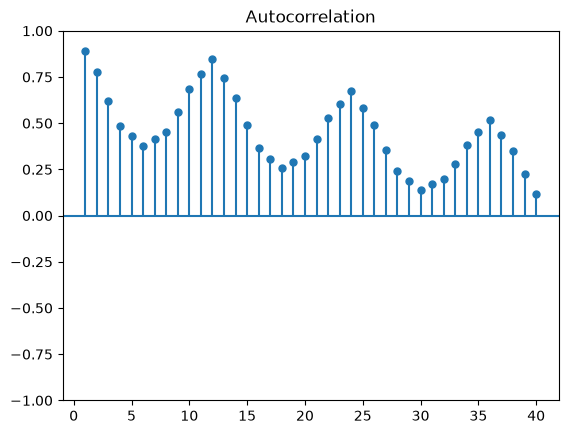

In [3]:
plot_acf(df['Milk'],lags=40,alpha=None,zero=False)
plt.show()

In [4]:
y = df['Milk']
y_train = y[:-12]
y_test = y[-12:]

# ARIMA

In [12]:
model = ARIMA(y_train,order=(2,1,1))
model_fit = model.fit()
print('Coefficient: %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train),end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,predictions)
print('Test RMSE : %.3f' % error)

Coefficient: ar.L1       -0.087896
ar.L2        0.272233
ma.L1        0.120660
sigma2    1882.401208
dtype: float64
Test RMSE : 72.863


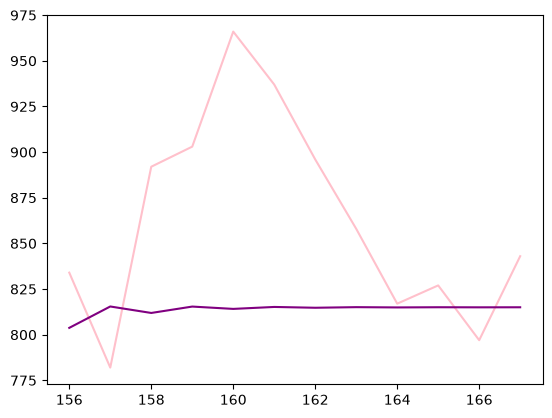

In [7]:
y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

# AutoARIMA

In [8]:
from pmdarima.arima import auto_arima

In [9]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.685, Time=0.74 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.32 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.30 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.73 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.322, Time=0.98 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.44 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.79 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.08 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1561.833, Time=1.00 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.84 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.06 s

In [11]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 57.878


## The ARIMA and Auto_arima gives us very bad rmse score because the data have seasonality

# Thats why we havd SARIMA 
### it adds seasonality

### we just add seasonality=True, and give m(period)= --

In [13]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True,seasonal=True,m=12)

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.22 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.60 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.54 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.04 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=1.81 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.51 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=2.85 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.53 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=5.67 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=1.23 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.30 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.65 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=2.15 sec
 ARIMA(1,0,2)(1,1,0)[12] int

In [16]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 13.941


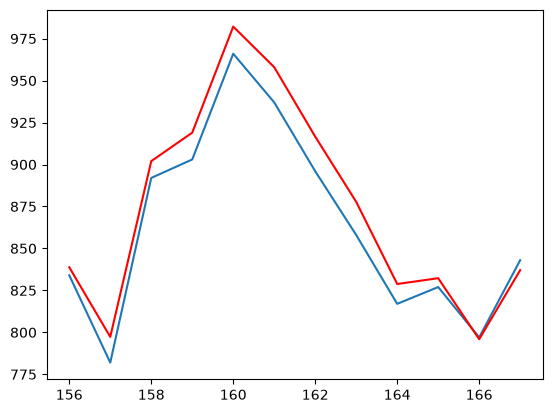

In [17]:
plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()